In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from hidro_tools import funcion_objetivo
from hidro_tools import funciones_hidrologicas
from pysheds.grid import Grid
from pysheds.view import Raster, ViewFinder
import funciones_chirps as fc
import delimitacion_cuenca as dc
from pathlib import Path
import xarray as xr
import rioxarray 
import glob
import re
import random
import os
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
# Lectura de datos
df = pd.read_csv(
    '0022057010-Q_MEDIA_D.csv',
    index_col=0,
    parse_dates=True,
    usecols=[0,1]
)
df = df.resample('D').mean()

FileNotFoundError: [Errno 2] No such file or directory: '0022057010-Q_MEDIA_D.csv'

In [9]:
faltantes = df.isna().groupby(df.index.year).sum()
# ploteo de los faltantes
x = faltantes.index
y = faltantes.iloc[:,0]
plt.figure(figsize=(12,8))
plt.bar(x=x,height=y,color='black')
plt.ylabel('Faltantes',fontsize=16)
plt.yticks(size=13)
plt.xticks(size=13)
plt.grid(linestyle='--',color='grey')

NameError: name 'df' is not defined

## Delimitacion cuencas zona

In [12]:
crs = 9377
gdf = gpd.read_file('CNE_actualizado')
gdf = gdf.to_crs(crs)
mask = gdf['Codigo'] == '22057010'
est_piedra_cobre = gdf[mask].copy()
lon = est_piedra_cobre.get_coordinates().iloc[0,0]
lat = est_piedra_cobre.get_coordinates().iloc[0,1]

In [13]:
path = 'dem_region_v2.tif'
dem = xr.open_dataset(path,engine='rasterio')
dem = dem.rename({"band_data": "elevation"})
dem = dem['elevation'][0, :, :]
dem = dem.where(dem != 0)
dem = dem.rio.write_crs('EPSG:32618')          # CRS original (solo etiqueta)
dem = dem.rio.write_nodata(float('nan'), encoded=False)

dem_9377 = dem.rio.reproject(
    'EPSG:9377',
    resolution=30,   # ajusta a tu resolución original (m); evita celdas no cuadradas o remuestreo no deseado
)

In [ ]:
# Delimitacion cuencas
path_guardado = 'cuencas_estaciones'
estaciones = ['22057070','22057060']
path_estaciones = 'q_data'
files = os.listdir(path_estaciones)
for file in files:
    cod = file.split('-')[0][2:]
    if cod in estaciones:
        mask = gdf['Codigo'] == cod
        df_estacion = gdf[mask].copy()
        nombre = df_estacion['Nombre'].iloc[0] + '.tif'
        name_path = os.path.join(path_guardado,nombre)
        # Extraccion georreferenciacion
        lon = df_estacion.get_coordinates().iloc[0,0]
        lat = df_estacion.get_coordinates().iloc[0,1]
        # Punto de desfogue
        outlet_estacion = (float(lon), float(lat))
        # Delimitacion
        cuenca = dc.delimitacion_cuenca(
            dem_9377,
            outlet_estacion,
            name_path,
            True
        )

In [ ]:
outlet_estacion = (float(lon), float(lat))
cuenca = dc.delimitacion_cuenca(dem_9377,outlet_estacion,'cuenca_saldana.tif')

## Modelo Hidrológico 
Se ajustan modelos de lluvia escorrentía Velez et al (2000) y GR4J.
Insumos:
- Precipitación CHIRPS 1981 - 2026 promediada zonalmente a nivel de cuenca
- ETP: Inicialmente Cenicafé, para ajuste inicial, luego se pueden utilizar otras entradas como Turc, Hargreaves o Thornwaite

### Precipitación IDEAM

In [2]:
# Se recortan los datos del CNE con la cuenca de Saldaña
cuenca_saldana = gpd.read_file('cuenca_saldana')
cne = gpd.read_file('CNE_actualizado')
cne = cne.to_crs(cuenca_saldana.crs)
# Clipeo de los datos
cne_clipped = cne.clip(cuenca_saldana)
cne_clipped.loc[:,'Fecha_inst'] = pd.to_datetime(cne_clipped['Fecha_inst']) 

Cannot find header.dxf (GDAL_DATA is not defined)
C:\Users\USUARIO\AppData\Local\Temp\ipykernel_23692\1005381965.py:7: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cne_clipped.loc[:,'Fecha_inst'] = pd.to_datetime(cne_clipped['Fecha_inst'])


In [3]:
categorias = ['Pluviométrica','Pluviográfica']
mask = (cne_clipped['Categoria'].isin(categorias)) & \
    (cne_clipped['Estado'] == 'Activa') & \
    (cne_clipped['Fecha_inst'] <= pd.to_datetime('2000-01-01'))
    
estaciones_pptn = cne_clipped[mask] 
estaciones_pptn.set_index('Codigo',drop=True,inplace=True)

In [4]:
# Estacion IDEAM
path = 'pptn_colombia'
files = os.listdir(path)

dict_files = {
    'files_path' : [os.path.join(path,file) for file in files],
    'cods' : [file.split('@')[1].split('.')[0] for file in files]
}
df_files = pd.DataFrame.from_dict(dict_files)
# Actualizacion
df_files.set_index('cods',drop=True,inplace=True)
# join de los dataframes
estaciones_pptn['files_path'] = df_files['files_path'].copy()

c:\Users\USUARIO\miniconda3\envs\cds\Lib\site-packages\geopandas\geodataframe.py:1528: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


In [5]:
# Retener estaciones
columnas = ['Nombre','Fecha_inst','X','Y','files_path','geometry']
estaciones_pptn = estaciones_pptn[columnas]

In [6]:
# Fechas de las estaciones
fecha_minima = estaciones_pptn['Fecha_inst'].min()
fecha_superior = '2025-12-31'
date_range = pd.date_range(
    fecha_minima,
    fecha_superior,
    freq='D'
)

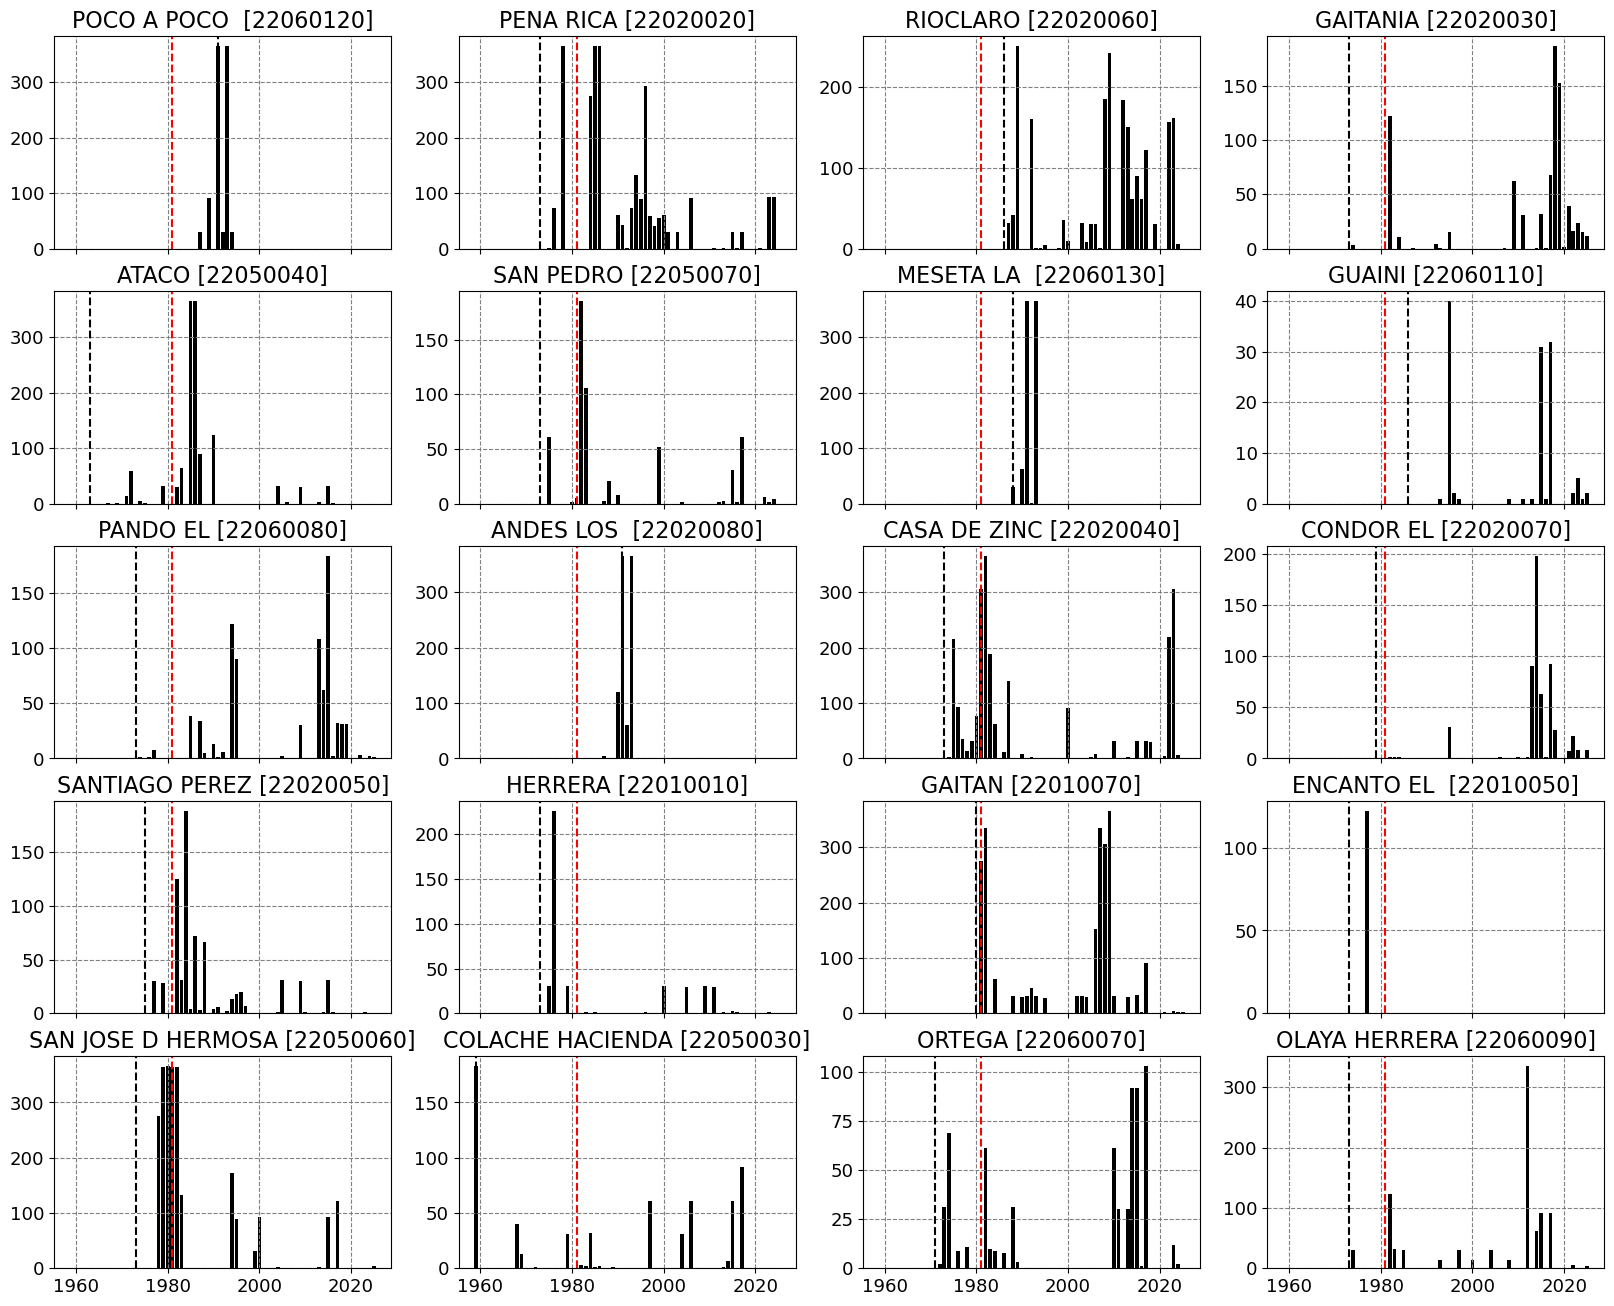

In [7]:
from hidro_tools import funciones_hidrologicas
# Chequeo de la consistencia de la informacion
figs, axes = plt.subplots(5,4,figsize=(20,16),sharex=True)
axis = axes.flatten()
fecha_chirps = 1981
for idx,cod in enumerate(estaciones_pptn.index):

    path_file = estaciones_pptn.at[cod,'files_path']
    fecha_estacion = estaciones_pptn.at[cod,'Fecha_inst'].year
    nombre = estaciones_pptn.at[cod,'Nombre']

    # Lectura de datos
    df = funciones_hidrologicas.read_data(path_file)
    # faltantes
    df_faltantes = df.isna().groupby(df.index.year).sum()
    # ploteo
    x = df_faltantes.index
    y = df_faltantes.iloc[:,0]
    axis[idx].bar(x=x,height=y,color='black')
    axis[idx].set_title(nombre,fontsize=16)
    # axis[idx].ylabel('Faltantes',fontsize=16)
    axis[idx].tick_params(axis='both', labelsize=13)
    axis[idx].grid(linestyle='--',color='grey')
    # Lineas chirps
    axis[idx].axvline(
        x=fecha_chirps,
        color='r',
        linestyle="--",
        linewidth=1.5, 
        label="CHIRPS"
    )
    # Linea estacion
    axis[idx].axvline(
        x=fecha_estacion,
        color='black',
        linestyle="--",
        linewidth=1.5, 
        label="estacion"
    )

### Precipitación Chirps

In [2]:
das = []
for f in sorted(glob.glob('chirps_tifs/chirps_*.tif')):
    da = rioxarray.open_rasterio(f)
    year = int(re.search(r'chirps_(\d{4})\.tif', f).group(1))
    fechas = pd.date_range(f'{year}-01-01', periods=da.sizes['band'], freq='D')
    das.append(da.assign_coords(band=fechas).rename(band='time'))

pptn = xr.concat(das, dim='time')

Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as 

In [3]:
# Cargar cuenca
path = 'cuenca_saldana'
cuenca_saldana = gpd.read_file(path)
# Cambiar crs
crs = pptn.rio.crs
cuenca_saldana = cuenca_saldana.to_crs(crs)

In [4]:
path = 'dem_region_v2.tif'
dem = xr.open_dataset(path,engine='rasterio')
dem = dem.rename({"band_data": "elevation"})
dem = dem['elevation'][0, :, :]
dem = dem.where(dem != 0)
dem = dem.rio.write_crs('EPSG:32618')          # CRS original (solo etiqueta)
dem = dem.rio.write_nodata(float('nan'), encoded=False)
dem = dem.rio.reproject('EPSG:9377', resolution=30)

In [5]:
def clip_a_cuenca(da, gdf):
    g = gdf.to_crs(da.rio.crs)
    return da.rio.clip(g.geometry.values, crs=da.rio.crs, drop=True)

In [6]:
clip_pptn = clip_a_cuenca(pptn, cuenca_saldana)
clip_dem  = clip_a_cuenca(dem, cuenca_saldana)

### Ajuste de sesgo

Chequear el numero de faltantes de cada estacion, se retienen aquellas con menos del 35% de faltantes.

In [30]:
estaciones_pptn = pd.read_csv('estaciones_pptn_saldana.csv',index_col=0)

In [46]:
pd.read_csv(estaciones_pptn['files_path'].iloc[3],index_col=0,parse_dates=True)

,22020030
1973-12-01 07:00:00,5.0
1973-12-02 07:00:00,4.0
1973-12-03 07:00:00,5.0
1973-12-04 07:00:00,5.0
1973-12-05 07:00:00,4.0
...,...
2025-06-30 07:00:00,NaN
2025-07-01 07:00:00,3.0
2025-07-02 07:00:00,9.0
2025-07-03 07:00:00,0.0


In [51]:
# Extraccion de faltantes
def faltantes(cod):
    path = estaciones_pptn.at[cod,'files_path']
    df = pd.read_csv(
        path,
        index_col=0,
        parse_dates=True
    )
    # ajuste a la resolucion de chirps
    df =  df.resample('D').mean()
    fecha = '1981-01-01'
    mask = df.index > fecha
    df_slice = df[mask]
    # faltantes
    faltantes = 100*(df_slice.isna().sum().iloc[0]/len(df_slice))
    faltantes = np.round(faltantes,2)
    return faltantes

estaciones_pptn['faltantes'] = estaciones_pptn.index.map(faltantes)

/tmp/ipykernel_7150/281108309.py:15: RuntimeWarning: invalid value encountered in scalar divide
  faltantes = 100*(df_slice.isna().sum().iloc[0]/len(df_slice))


In [49]:
# dropeo estaciones con muchos faltantes
umbral = 30
mask = estaciones_pptn['faltantes'] < umbral
estaciones_pptn_slice = estaciones_pptn[mask]

In [52]:
estaciones_pptn # Crear un dataset vacio

# Array vacio para luego interpolar
array = clip_pptn[0,:,:] * 0 + np.nan

for idx,cod in enumerate(estaciones_pptn_slice.index):
    
    # Lectura de los datos
    path = estaciones_pptn_slice.at[cod,'files_path']

    df = pd.read_csv(
        path,
        index_col=0,
        parse_dates=True
    )
    # ajuste a la resolucion de chirps
    df =  df.resample('D').mean()
    
    # codigo = re.findall(re_pattern, prueba)[0]
    pptn_anual_ideam = funciones_hidrologicas.pptn_media_anual(df)
    # extraccion de los datos
    coord_x = estaciones_pptn_slice.loc[cod,'X']
    coord_y = estaciones_pptn_slice.loc[cod,'Y']
    # Extraccion de datos chirps
    pptn_chirps = clip_pptn.sel(
        x=coord_x,
        y=coord_y,
        method='nearest'
    )
    df_pptn_chirps = pptn_chirps.to_dataframe('pptn')
    df_pptn_chirps = df_pptn_chirps[['pptn']]
    # Estimacion media 
    media_chirps = funciones_hidrologicas.pptn_media_anual(df_pptn_chirps)
    # estimacion correccion
    correccion = pptn_anual_ideam/media_chirps
    # seleccion puntos array
    x_array = array.x.sel(
        x=coord_x,
        method='nearest'
    )
    y_array = array.y.sel(
        y=coord_y,
        method='nearest'
    )
    #diccionario asignacio datos
    dict_arreglo = dict(
        x=x_array,
        y=y_array
    )
    # asignacion
    array.loc[dict_arreglo] = correccion

In [53]:
arreglo_sesgo = fc.idw_interpolate_dataarray(array)

In [54]:
# correccion precipitacion
clip_pptn = clip_pptn * arreglo_sesgo

### Modelo de Tanques

#### Calibracion

In [122]:
dict_fechas = {
    '22057070':('2005','2015'),
    '22057060':('2000','2010'),
    '22057010':('2005','2015')
}
dict_area = {
    '22057070':6422.64,
    '22057060':4408.76,
    '22057010':7742.234,
}
path_cuencas = {
    '22057070':'cuencas_estaciones/pte_colache.shp',
    '22057060':'cuencas_estaciones/la_muralla.shp',
    '22057010':'cuenca_saldana/cuenca_saldana.shp',
}
path_data = {
    '22057070':'q_data/0022057070-Q_MEDIA_D.csv',
    '22057060':'q_data/0022057060-Q_MEDIA_D.csv',
    '22057010':'q_data/0022057010-Q_MEDIA_D.csv',
}

In [123]:
def clip_a_cuenca(da, gdf):
    g = gdf.to_crs(da.rio.crs)
    return da.rio.clip(g.geometry.values, crs=da.rio.crs, drop=True)

def read_q_data(cod):
        # Lectura de datos
    df_q = pd.read_csv(
        path_data[cod],
        index_col=0,
        parse_dates=True,
        usecols=[0,1]
    )
    df_q = df_q.resample('D').mean()

    return df_q

In [136]:
from hidro_tools import funcion_objetivo   # ajusta a tu estructura
from hidro_tools import modelo_tanques
MT = modelo_tanques.modelo_tanques

resultados, dict_simulaciones = {}, {}
cods = ['22057070','22057010']
pesos = {'Nash': 0.0, 'Nash_mod': 0.7, 'Balance': 0.15}
dict_q_obs = dict()
dict_pptn = dict()
dict_sim = dict()
dict_puntaje = dict()
dict_mejores = dict()
for cod in cods:

    # Lectura de datos
    df_q = read_q_data(cod)
    # Preparacion de la informacion
    fecha_i,fecha_f = dict_fechas[cod]
    mask = (df_q.index >= fecha_i) & (df_q.index < fecha_f)
    q_obs = np.asarray(df_q[mask].iloc[:,0])
    dict_q_obs[cod] = q_obs
    # Delimitacion de la cuenca 
    gdf = gpd.read_file(path_cuencas[cod])
    # arreglo precipitacion
    da_pptn = clip_a_cuenca(clip_pptn,gdf)
    da_pptn_cuenca = da_pptn.mean(axis=1).mean(axis=1)
    df_pptn = da_pptn_cuenca.to_dataframe('pptn')
    mask = (df_pptn.index >= fecha_i) & (df_pptn.index < fecha_f)
    pptn_cuenca = (df_pptn[mask].iloc[:,1])
    dict_pptn[cod] = pptn_cuenca
    # Cota 
    clip_dem = clip_a_cuenca(clip_dem,gdf)
    cota = clip_dem.mean(axis=0).mean(axis=0).values

    dict_mejores[cod], dict_sim[cod], dict_puntaje[cod] = MT.calibrar(
    pptn_cuenca, q_obs, cota, dict_area[cod],
    fobj=funcion_objetivo,
    fijos={'perdidas_subt': 0},
    calentamiento=180,
    maxiter=5000,
    seed=42,
    pesos = pesos,
    )

    # resultados[cod], dict_simulaciones[cod] = MT.montecarlo(
    #     pptn_cuenca, 
    #     q_obs,
    #     cota,            # en vez del 2134.65 fijo
    #     area=dict_area[cod],
    #     fobj=funcion_objetivo,
    #     n_iter=5000,
    #     fijos={'perdidas_subt': 0},     # opcional
    #     calentamiento=180,              # opcional, días excluidos de las métricas
    #     seed=42,                        # opcional, para repetir la corrida
    # )

In [137]:
dict_puntaje

{'22057070': np.float64(0.19883140477242425),
 '22057010': np.float64(0.2651806421555019)}

In [140]:
# Chequeo resultados'
cod = '22057070'
# df = resultados[cod]
q_obs_ = dict_q_obs[cod]
q_sim = dict_sim[cod]
pptn_cuenca_ = dict_pptn[cod]
mejor_params = dict_mejores[cod]
  # mismo índice que el DataFrame

In [95]:
# Corridas "aceptables" según el artículo (BE < 10 %, E2 > 40 %)
buenas = df[(df['Balance'] < 10) & (df['Nash_mod'] > 0.30)]

# La mejor por Nash modificado
idx = df['Nash_mod'].idxmax()
mejor = df.loc[idx]
q_sim_mejor = dict_simulaciones[cod][idx] 

KeyError: 'Balance'

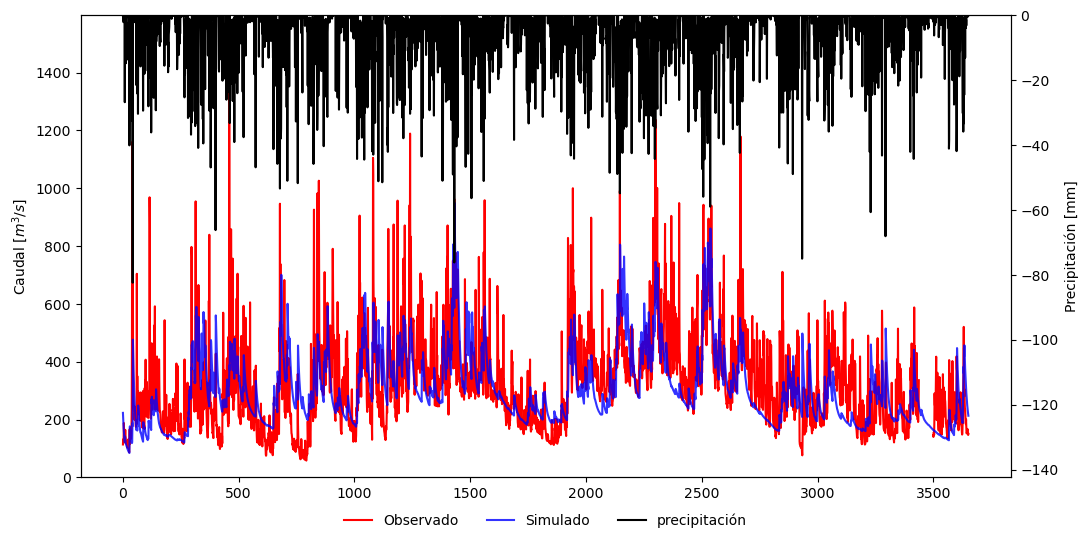

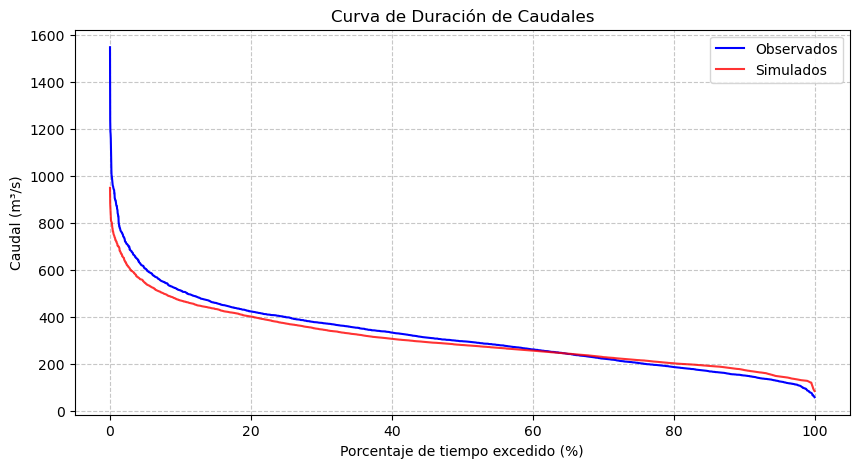

In [141]:
# params = [mejor_params[k] for k in MT.NOMBRES_PARAMS]
# modelo = MT(pptn_cuenca_, *params, cota, dict_area[cod],
#             cond_ini=mejor['cond_iniciales'])
# q_sim, q_base = modelo.correr()

MT.plot_resultados(None,q_obs_, q_sim, pptn_cuenca_)
MT.curva_duracion(None,q_obs_, q_sim)

In [19]:
path_estaciones = 'q_data'
files = os.listdir(path_estaciones)

#### Chequeo resultados

In [48]:
MT = modelo_tanques.modelo_tanques

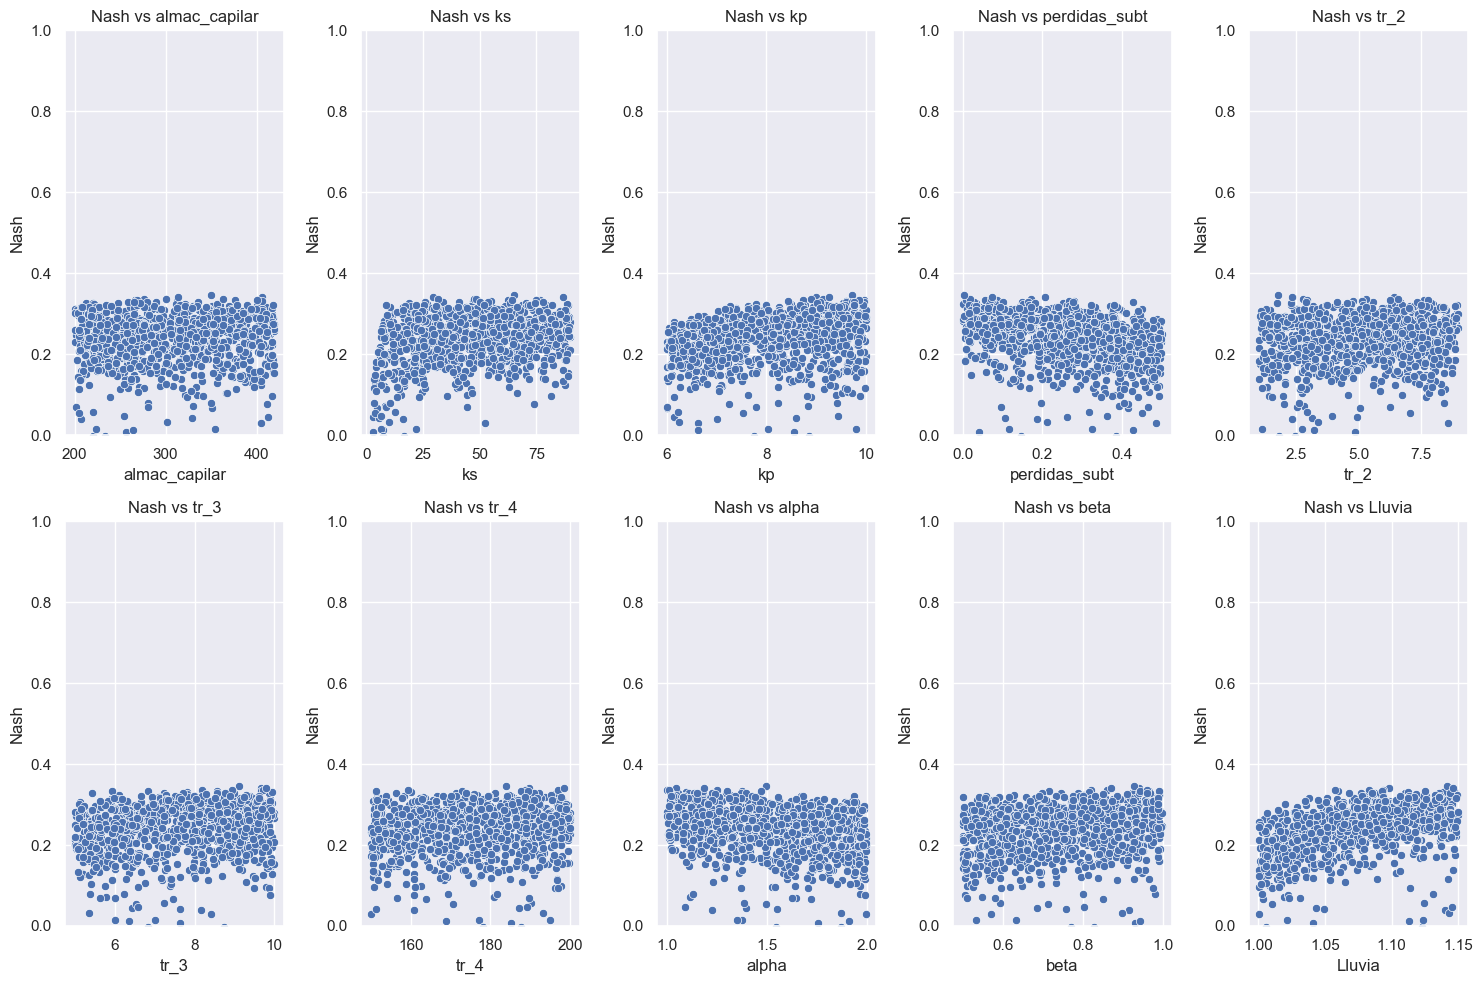

In [93]:
import seaborn as sns
fig, axes = plt.subplots(2, 5, figsize=(15, 10))  # Ajusta según el número de variables
axes = axes.flatten()

# Iterar sobre las columnas excepto 'Nash'
for i, col in enumerate(df_resultados.columns[:-7]):
    sns.scatterplot(data=df_resultados, x=col, y='Nash', ax=axes[i])
    axes[i].set_title(f'Nash vs {col}')
    axes[i].set_ylim(0,1)

# Ajuste de diseño
plt.tight_layout()
plt.show()

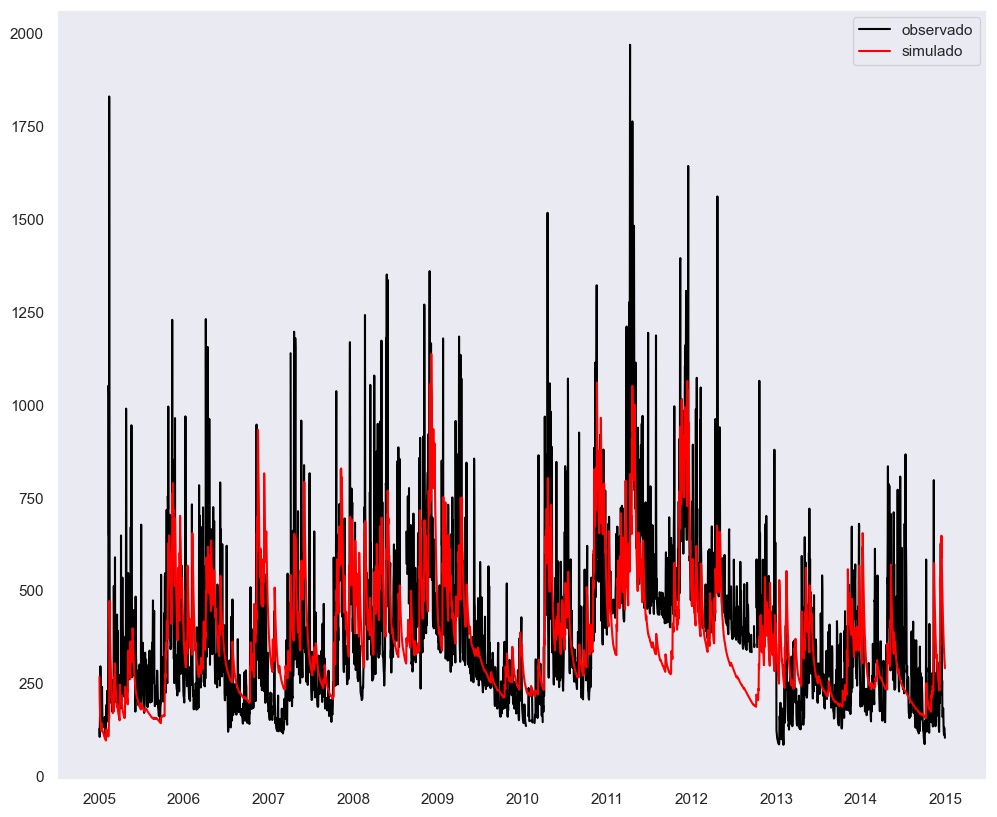

In [94]:
mask = df_resultados['Nash'] == df_resultados['Nash'].max()
mejor_ajuste = df_resultados[mask] 
id = mejor_ajuste.index[0]
t = pd.date_range(t_inicial,periods=10*365,freq='D')
plt.figure(figsize=(12,10))
plt.plot(t,q_cal,color='black',label='observado')
plt.plot(t,simulaciones[id],color='red',label='simulado')
plt.legend()
plt.grid()

In [100]:
mejor_ajuste

,almac_capilar,ks,kp,perdidas_subt,tr_2,tr_3,tr_4,alpha,beta,Lluvia,cond_iniciales,Nash,Nash_mod,rmse,rmse_mod,Balance,q_05
605,349.795359,65.27461,9.724187,0.003983,1.78011,9.123964,183.97093,1.493951,0.929009,1.141689,"[174.89767945566672, 1.7801096687021571, 9.123...",0.34571,0.35269,177.327,4.08,3.264169,19.372842


### Modelo GR4J

In [71]:
from hidro_tools import gr4j

In [72]:
def monte_carlo():
    # Se aplican los intervalos sugeridos en (Perrin, 2003)
    X1 = random.uniform(100, 1200) #100 - 1200
    X2 = random.uniform(-5, 3) #-5 - 3
    X3 = random.uniform(20, 300) #20 - 300
    X4 = random.uniform(1.1, 2.9) #1.1-2.9

    return X1,X2,X3,X4

def datos_iniciales():
    # Define las condiciones iniciales para el modelo
    x1 = random.uniform(0.6,0.8)
    x3 = random.uniform(0.6,0.8)

    return x1,x3

# Se ingresa el área de la cuenca
Area = 7742.234 #Km2
# Evapotranspiracion potencial
etp = 4.658*np.exp(-0.0002*(2134.65))
# Datos entrada para calibracion
etp_array_cal = np.ones_like(pptn_cal)*etp
# etp_array_cal = np.array(pet_data_entrada['Value'])
# q_obs = np.array(q_acotado['Valor'])[0:3649]
q_obs = q_cal.copy()
# Parametros Extraidos de la simulacion

#Ciclo for para generar simulaciones 

# Diccionario que almacena los resultados de las iteraciones

resultados = {

    'X1':[],
    'X2':[],
    'X3':[],
    'X4':[],
    'CI_X1':[],
    'CI_X3':[],
    'FO1':[],
    'FO2':[],
    'FO3':[],    
}

# Lista que almacena los caudales simulados

simulaciones = [

]

# Se inicia con 2000 simulaciones
for i in range(1000):
    params = monte_carlo()

    dic_params = {
        'X1':params[0],  # 100-1200
        'X2':params[1],  # -5 a 3
        'X3':params[2],  # 20-300
        'X4':params[3],  # 1.1-2.9
    }

    # Genera el porcentaje de inicio del production store y el routing store
    x1,x3 = datos_iniciales()

    # Condicione iniciales para ingreso al modelo
    cond_iniciales = {

            'production_store': x1 * params[0],
            'routing_store': x3 * params[2]
    }

    # Se almacenan las condiciones iniciales
    resultados['CI_X1'].append(x1)
    resultados['CI_X3'].append(x3)

    q_simulado = np.array(gr4j.gr4j(pptn_cal,
                                  etp_array_cal,
                                  dic_params,
                                  cond_iniciales))
    
    # La Salida del modelo se da en mm, por lo cual se multiplica por el área de la cuenca y se divide por el factor de escalamiento
    q_simulado_escalado = q_simulado*(Area)/86.4
    
    # Se almacenan las simulaciones
    simulaciones.append(q_simulado_escalado)
    
    # Almacenamiento de resultados
    resultados['X1'].append(params[0])      
    resultados['X2'].append(params[1])  
    resultados['X3'].append(params[2])  
    resultados['X4'].append(params[3])

    # Almacenamiento resultados del nash
    resultados['FO1'].append(funcion_objetivo.nash_sqrt(q_obs,q_simulado_escalado))
    resultados['FO2'].append(funcion_objetivo.nash_log(q_obs,q_simulado_escalado))
    resultados['FO3'].append(funcion_objetivo.nash(q_obs,q_simulado_escalado))

In [98]:
resultado_mc = pd.DataFrame.from_dict(resultados)
mask = resultado_mc['FO3'] == max(resultado_mc['FO3']) 
resultado_mc[mask]

,X1,X2,X3,X4,CI_X1,CI_X3,FO1,FO2,FO3
51,1104.141437,2.67429,145.126295,1.137424,0.746483,0.66355,0.1673,-0.13999,0.32828


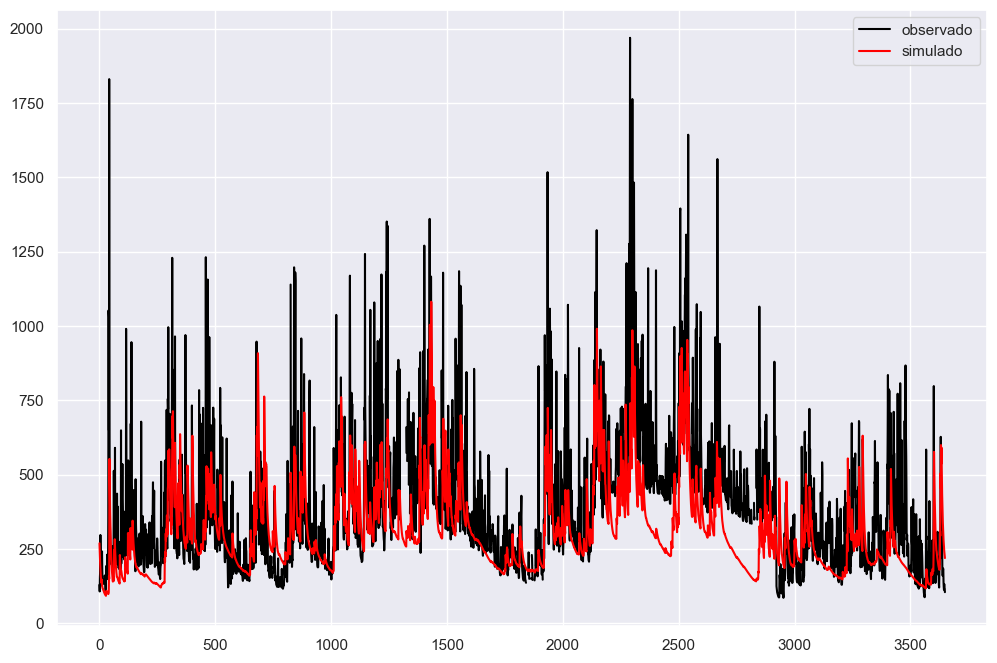

In [99]:
q_sim = simulaciones[51]
plt.figure(figsize=(12,8))
plt.plot(q_cal,color='black',label='observado')
plt.plot(q_sim,color='red',label='simulado')
plt.legend()

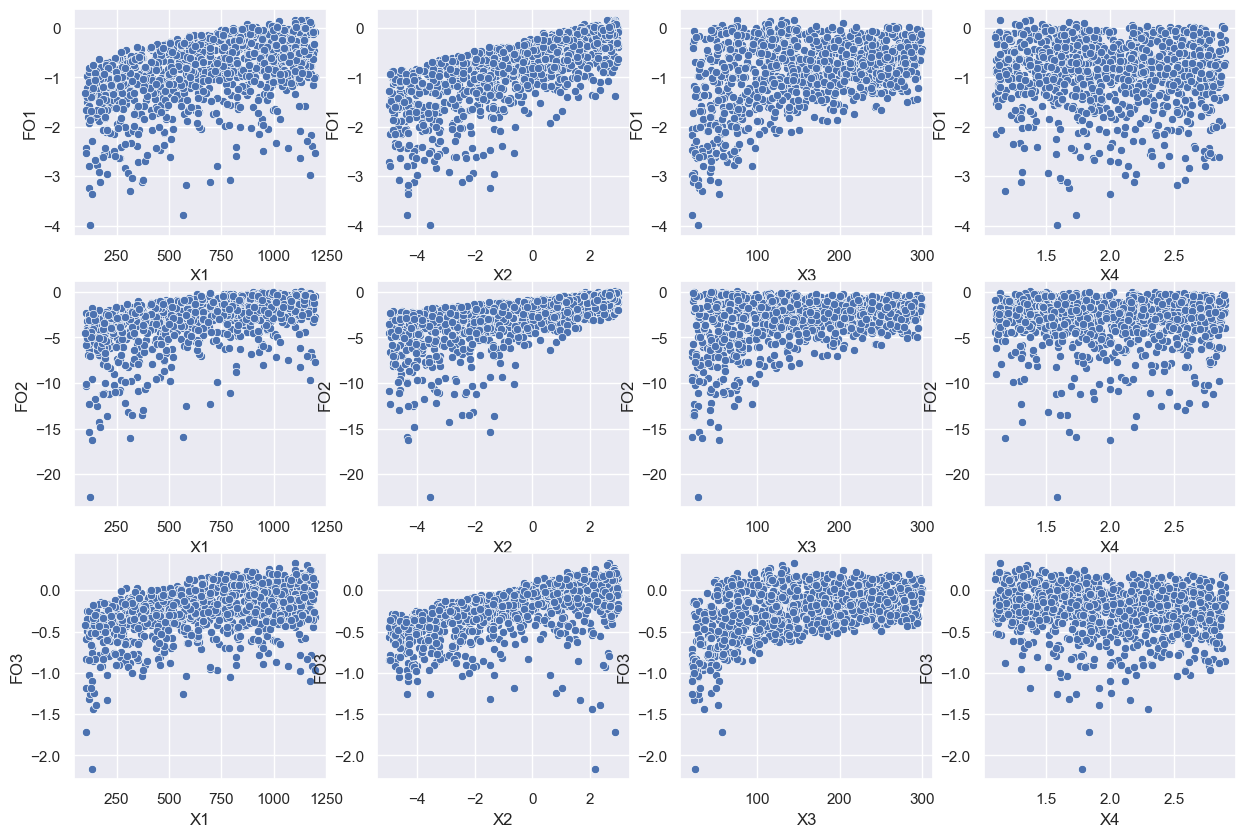

In [96]:

# Figuras de sensibilidad 
sns.set()
fig, axes = plt.subplots(
    3,4,
    figsize=(15,10),
    )


# Lista con 
params = list((resultado_mc.columns))[0:4]
fun_obj = list((resultado_mc.columns))[6:10]

for i in range(len(fun_obj)):
    for j in range(len(params)):

        # se crean los graficos
        sns.scatterplot(
            data=resultado_mc,
            x=params[j], 
            y=fun_obj[i],
            ax=axes[i,j]
        )

### Modelo machine learning
Para el modelo se planean utilizar serie de precipitación de toda la cuenca al igual que las estaciones de caudal aguas arriba de la estación Punta de Cobre 

#### Análisis de caudales

In [45]:
path = 'q_data'
files_estaciones = os.listdir(path)

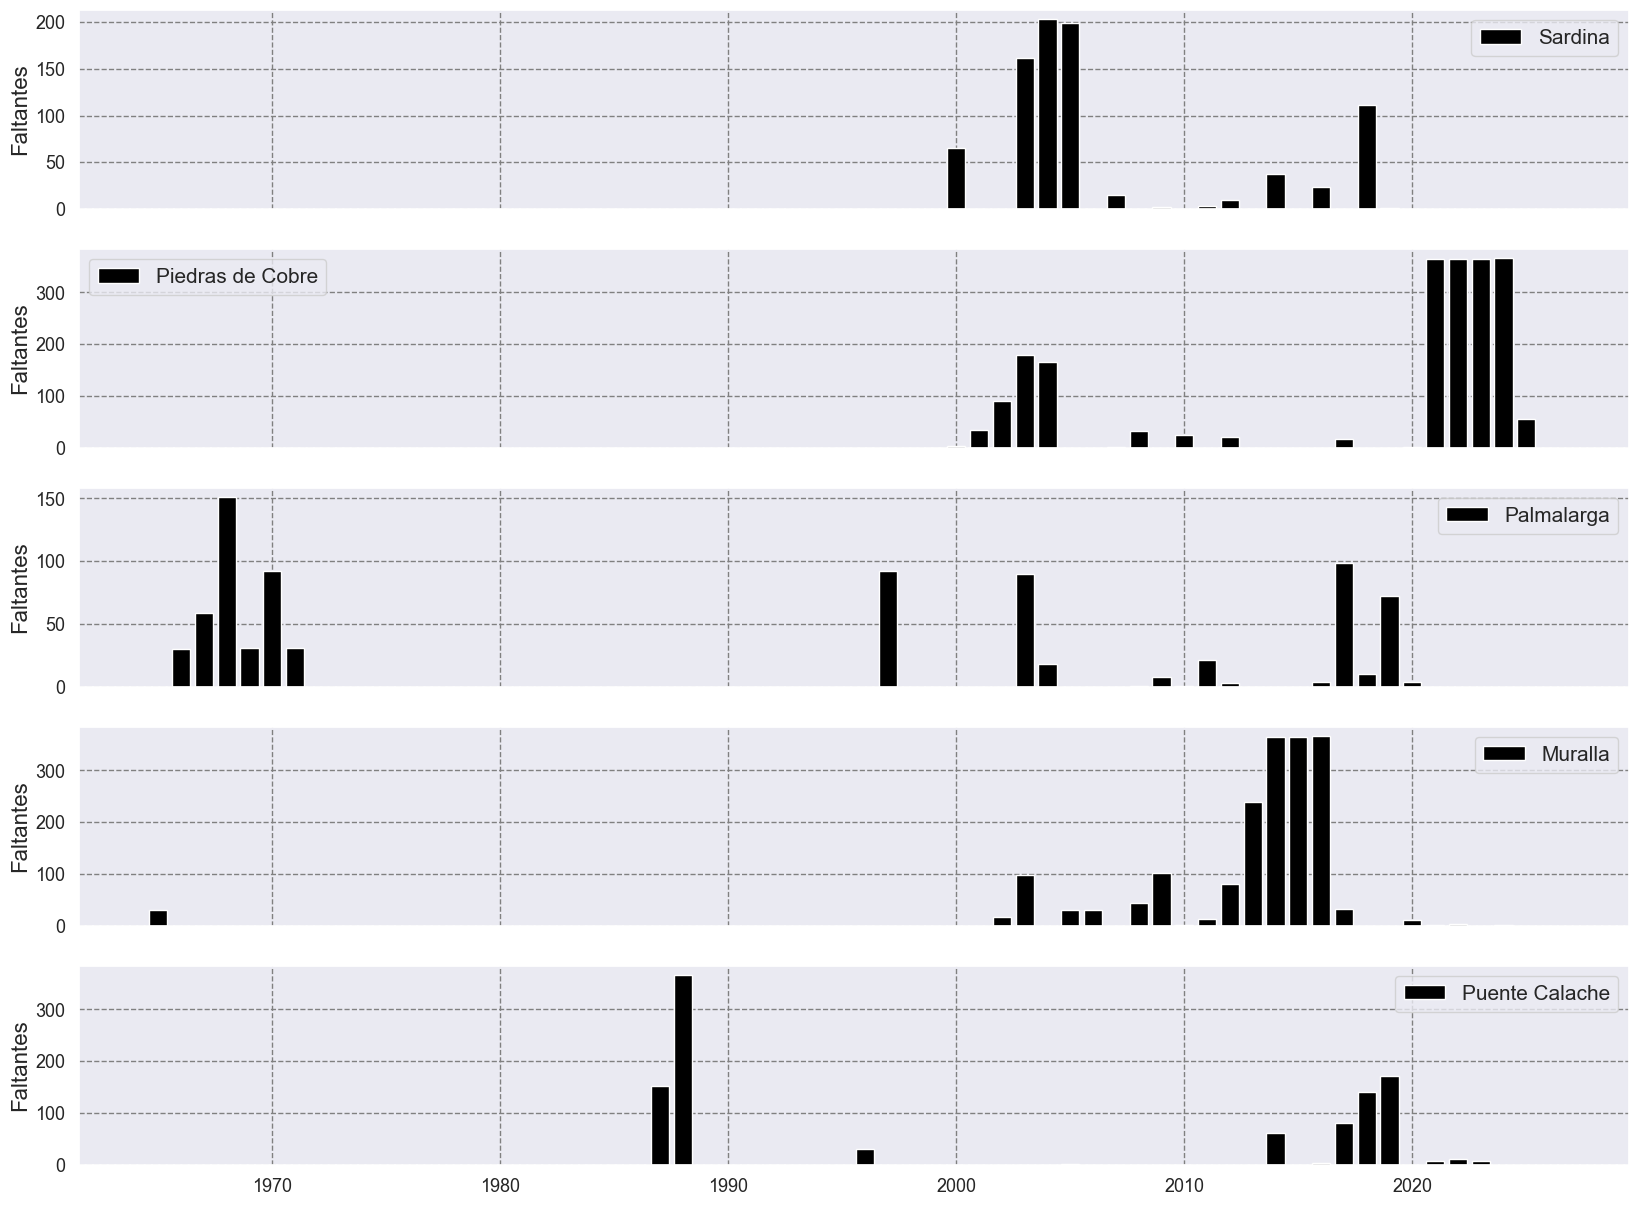

In [66]:
# Chequeo de datos faltantes
estaciones = {
    '0022017020':'Sardina',
    '0022057010':'Piedras de Cobre',
    '0022057040':'Palmalarga',
    '0022057060':'Muralla',
    '0022057070':'Puente Calache'
}
path_files = r'C:\Users\USUARIO\Documents\saldana_modelo\hidrologia_saldana\hidrologia_saldana\q_data'
# Chequeo de registro y datos faltantes
fig, axes = plt.subplots(5,1,figsize=(20,15),sharex=True)
axis = axes.flatten()
for idx,file in enumerate(files_estaciones):
    file_path = os.path.join(path_files,file)
    # Lectura de datos
    df = pd.read_csv(
        file_path,
        index_col=0,
        parse_dates=True,
        usecols=[0,1]
    )
    # Nombre de la estacion
    estacion_cod = file.split('-')[0]
    estacion_nombre = estaciones[estacion_cod]
    df = df.resample('D').mean()
    faltantes = df.isna().groupby(df.index.year).sum()
    # ploteo de los faltantes
    x = faltantes.index
    y = faltantes.iloc[:,0]
    axis[idx].bar(x=x,height=y,color='black',label=estacion_nombre)
    axis[idx].legend(fontsize=15)

    axis[idx].set_ylabel('Faltantes',fontsize=16)
    axis[idx].tick_params(axis='both', labelsize=13)
    axis[idx].grid(linestyle='--',color='grey')